# Training

In [2]:
# import the libs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.tree import plot_tree
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

exo_plnt = pd.read_csv(r"C:\Users\vaibh\AI_ML\Project\Visualization and data cleaning\Cleaned_dataset.csv")
exo_plnt

,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_tce_plnt_num,koi_steff,koi_slogg,koi_srad,koi_kepmag,encoded_disposition
0,9.488036,0.146,2.95750,615.8,2.26,793.0,93.59,35.8,1.0,5455.0,4.467,0.927,15.347,1
1,54.418383,0.586,4.50700,874.8,2.83,443.0,9.11,25.8,2.0,5455.0,4.467,0.927,15.347,1
2,19.899140,0.969,1.78220,10829.0,14.60,638.0,39.30,76.3,1.0,5853.0,4.544,0.868,15.436,0
3,1.736952,1.276,2.40641,8079.2,33.46,1395.0,891.96,505.6,1.0,5805.0,4.564,0.791,15.597,0
4,2.525592,0.701,1.65450,603.3,2.75,1406.0,926.16,40.9,1.0,6031.0,4.438,1.046,15.509,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6804,23.627035,1.096,11.48100,8433.0,21.71,560.0,23.17,78.4,1.0,5305.0,4.477,0.857,16.375,0
6805,8.589871,0.765,4.80600,87.7,1.11,929.0,176.40,8.4,1.0,5638.0,4.296,1.088,14.478,0
6806,0.527699,1.252,3.22210,1579.2,29.35,2088.0,4500.53,453.3,1.0,5638.0,4.529,0.903,14.082,0
6807,0.681402,0.147,0.86500,103.6,1.07,2218.0,5713.41,12.3,1.0,6173.0,4.447,1.041,15.385,0


In [5]:
# splitting the data
X_train, X_test, y_train, y_test = train_test_split(
    exo_plnt.drop(columns='encoded_disposition'),
    exo_plnt['encoded_disposition'], 
    test_size=0.2, 
    random_state=42
)

In [13]:
# intitializing the model
model = RandomForestClassifier()

# training
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
# testing
# predictions = model.predict(X_test)

custom_predictions = (model.predict_proba(X_test)[:, 1] >= 0.35).astype(int)

In [15]:
# performance metrics
confusion_mat = confusion_matrix(y_test, custom_predictions)
print('Confusion Matrix: \n', confusion_mat)
print('Classification Report: \n', classification_report(y_test, custom_predictions))

Confusion Matrix: 
 [[806  84]
 [ 33 439]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.96      0.91      0.93       890
           1       0.84      0.93      0.88       472

    accuracy                           0.91      1362
   macro avg       0.90      0.92      0.91      1362
weighted avg       0.92      0.91      0.92      1362



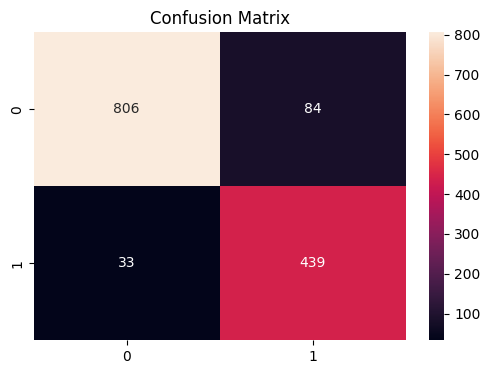

In [16]:
# confusion matrix heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_mat, 
    annot=True, 
    fmt='g'
)

plt.title('Confusion Matrix')

plt.savefig('Confusion_matrix.png', dpi=1000)

plt.show()

In [17]:
# pickling the trained model
joblib.dump(model, 'exoplanet_model.pkl')

print('Model saved successfully!')

Model saved successfully!


In [18]:
# finding meadians of all columns
exo_plnt.median(axis=0)

koi_period                7.834434
koi_impact                0.587000
koi_duration              3.890000
koi_depth               515.200000
koi_prad                  2.720000
koi_teq                 939.000000
koi_insol               183.480000
koi_model_snr            32.100000
koi_tce_plnt_num          1.000000
koi_steff              5774.000000
koi_slogg                 4.438000
koi_srad                  1.000000
koi_kepmag               14.492000
encoded_disposition       0.000000
dtype: float64

In [21]:
print(custom_predictions)
model.predict_proba(X_test)

[1 0 1 ... 1 0 0]


array([[0.47, 0.53],
       [0.98, 0.02],
       [0.59, 0.41],
       ...,
       [0.01, 0.99],
       [0.98, 0.02],
       [0.66, 0.34]], shape=(1362, 2))

c:\Users\vaibh\AI_ML\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.7.2 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\vaibh\AI_ML\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.7.2 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


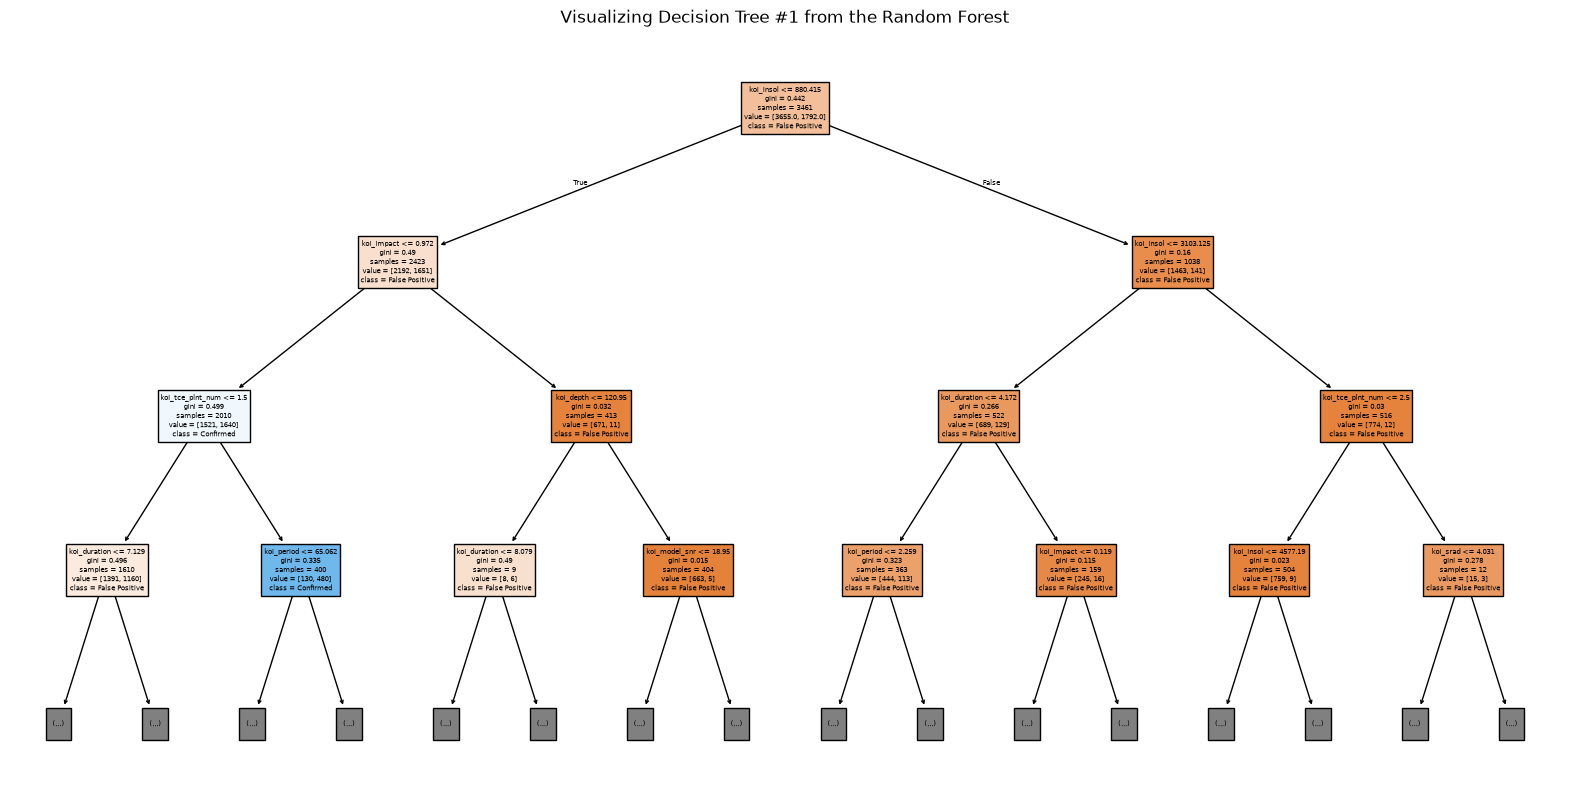

In [7]:
model = joblib.load(r"C:\Users\vaibh\AI_ML\Project\Training\exoplanet_model.pkl")

# 1. Set up a large figure size so you can read the text
plt.figure(figsize=(20, 10))

# 2. Plot the first tree in your Random Forest
plot_tree(
    model.estimators_[0],          # Pulls the 1st tree (change 0 to 1, 2, etc. for others)
    feature_names=X_train.columns, # Labels the splits with your feature names (e.g., koi_depth)
    class_names=['False Positive', 'Confirmed'], # Labels the predictions
    filled=True,                   # Colors the nodes (blue for Confirmed, orange for False Positive)
    max_depth=3                    # Limits the view to the top 3 levels so it is readable
)

plt.title("Visualizing Decision Tree #1 from the Random Forest")

plt.savefig('decision_tree1.png', dpi=1000)
plt.show()
